# Model Analysis — `models/chosen_model/CNN2kernel_0.8.pt`

Evaluates the chosen checkpoint on the benchmark dataset and reports:

- **Model size** — number of trainable parameters
- **AUROC** and **AUPRC** (residue-level and protein-level)
- All other standard metrics (accuracy, precision, recall, F1) as bar plots

The benchmark uses the same clipped `2k+1` sliding-window scoring as `src/predict.py`: for every residue, ESM2 embeds the centred window live and the CNN outputs a core probability.

In [22]:
import os, sys, json
import numpy as np
import torch
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
)

sys.path.insert(0, os.path.abspath(".."))
from src.predict import load_model, score_protein, core_mask, longest_positive_run, DEFAULT_BENCHMARK

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CHECKPOINT = "../models/chosen_model/CNN2kernel_0.8.pt"
K = 8                 # window half-width (window = 2k+1), matches src/predict.py default
THRESHOLD = 0.5        # per-residue core-probability threshold
MIN_CORE_LEN = 5      # min consecutive run above threshold -> protein predicted AMYLOID

print(f"device: {DEVICE}")

device: cpu


In [24]:
model, max_len = load_model(CHECKPOINT, DEVICE)
n_params = sum(p.numel() for p in model.parameters())
n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"checkpoint   : {CHECKPOINT}")
print(f"max_len      : {max_len}")
print(f"total params : {n_params:,}")
print(f"trainable    : {n_trainable:,}")
print(model)

checkpoint   : ../models/chosen_model/CNN2kernel_0.8.pt
max_len      : 20
total params : 492,801
trainable    : 492,801
_AmyloidClassifier(
  (encoder): _SimCLREncoder(
    (features): Sequential(
      (0): MultiKernelConvBlock(
        (branches): ModuleList(
          (0): Conv1d(480, 128, kernel_size=(3,), stride=(1,), padding=(1,))
          (1): Conv1d(480, 128, kernel_size=(5,), stride=(1,), padding=(2,))
        )
        (bn): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (act): ReLU()
      )
    )
    (pool): GlobalPool(
      (maxp): AdaptiveMaxPool1d(output_size=1)
      (avgp): AdaptiveAvgPool1d(output_size=1)
    )
  )
  (head): Linear(in_features=512, out_features=1, bias=True)
)


## Benchmark inference

Live ESM2 scoring of every protein in the benchmark set; may take a while on CPU.

In [25]:
with open(f"../{DEFAULT_BENCHMARK}") as fh:
    proteins = json.load(fh)
print(f"{len(proteins)} benchmark proteins")

prot_true, prot_pred, prot_score = [], [], []

for p in proteins:
    prob = score_protein(p["Sequence"], model, K, max_len, DEVICE)

    run = longest_positive_run(prob >= THRESHOLD)
    prot_pred.append(1 if run >= MIN_CORE_LEN else 0)
    prot_true.append(1 if p["LABEL"] == "AMYLOID" else 0)
    prot_score.append(float(prob.max()))   # continuous protein-level score for AUROC/AUPRC

prot_true  = np.array(prot_true)
prot_pred  = np.array(prot_pred)
prot_score = np.array(prot_score)

print("done")

28 benchmark proteins
done


In [27]:
def compute_metrics(y_true, y_pred, y_score):
    return {
        "accuracy" : accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall"   : recall_score(y_true, y_pred, zero_division=0),
        "f1"       : f1_score(y_true, y_pred, zero_division=0),
        "roc_auc"  : roc_auc_score(y_true, y_score) if len(np.unique(y_true)) > 1 else float("nan"),
        "pr_auc"   : average_precision_score(y_true, y_score) if len(np.unique(y_true)) > 1 else float("nan"),
    }

protein_metrics = compute_metrics(prot_true, prot_pred, prot_score)
print("Protein-level classification (AMYLOID vs NONAMYLOID):")
print({k: round(v, 4) for k, v in protein_metrics.items()})

Protein-level classification (AMYLOID vs NONAMYLOID):
{'accuracy': 0.75, 'precision': 0.6667, 'recall': 1.0, 'f1': 0.8, 'roc_auc': 0.8112, 'pr_auc': 0.8225}


## Bar plot — Classification Metrics

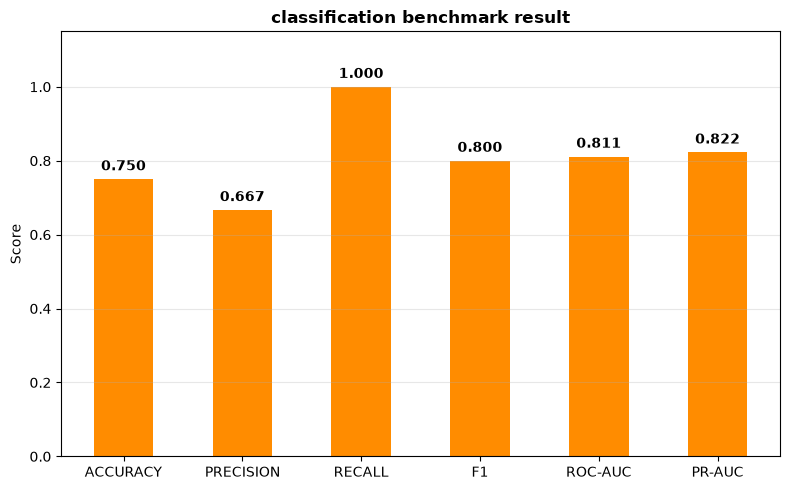

In [28]:
metric_names = ["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]
x = np.arange(len(metric_names))
values = [protein_metrics[m] for m in metric_names]

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(x, values, width=0.5, color="darkorange")

for b, v in zip(bars, values):
    ax.annotate(f"{v:.3f}", (b.get_x() + b.get_width() / 2, b.get_height()),
                xytext=(0, 4), textcoords="offset points",
                ha="center", va="bottom", fontsize=10, fontweight="bold")

ax.set_xticks(x)
ax.set_xticklabels([m.upper().replace("_", "-") for m in metric_names])
ax.set_ylabel("Score")
ax.set_ylim(0, 1.15)
ax.set_title(f"classification benchmark result", fontweight="bold")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("../models/chosen_model/benchmark_metrics.png", dpi=150, bbox_inches="tight")
plt.show()

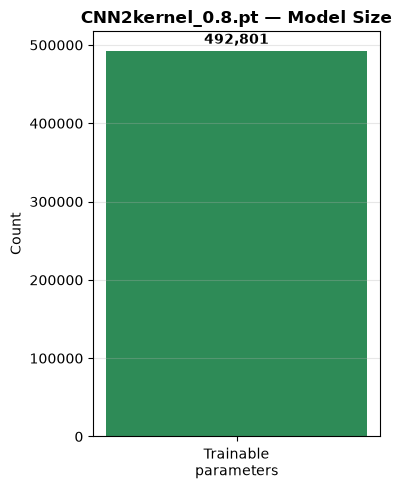

In [29]:
fig, ax = plt.subplots(figsize=(4, 5))
bar = ax.bar(["Trainable\nparameters"], [n_trainable], color="seagreen", width=0.5)
ax.annotate(f"{n_trainable:,}", (bar[0].get_x() + bar[0].get_width() / 2, n_trainable),
            xytext=(0, 5), textcoords="offset points", ha="center", fontweight="bold")
ax.set_ylabel("Count")
ax.set_title(f"{os.path.basename(CHECKPOINT)} — Model Size", fontweight="bold")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("../models/chosen_model/model_size.png", dpi=150, bbox_inches="tight")
plt.show()

## Save metrics to CSV (same schema as `results/*/..._metrics.csv`)

In [ ]:
rows = [("classification", k, v) for k, v in protein_metrics.items()]
rows += [("model", "trainable_params", n_trainable), ("model", "total_params", n_params)]

import csv
out_csv = "../models/chosen_model/benchmark_metrics.csv"
with open(out_csv, "w", newline="") as fh:
    writer = csv.writer(fh)
    writer.writerow(["scope", "metric", "value"])
    writer.writerows(rows)

print(f"saved {out_csv}")